<a href="https://colab.research.google.com/github/EugeneOny1/-civil-infrastructure-monitoring---CS-PROJECT-II/blob/feature-branch/07_inference_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 07 — Inference Demo and Model Export

This notebook:
1. exports the trained checkpoint as a TensorFlow SavedModel;
2. optionally converts it to TFLite;
3. inspects the exported signatures/tensors;
4. runs sample inference;
5. produces the model artifact required by the Flask application.

### Final AI output
- defect class
- confidence
- bounding box

The web application's relative visual severity calculation is a separate backend step.

In [1]:
# ---------------------------------------------------------
# Notebook 07 setup: Drive + isolated TensorFlow 2.15 environment
# ---------------------------------------------------------


import os
import sys
import shutil
import subprocess
from pathlib import Path

TFOD_ENV = Path("/content/tfod_env")

if not (TFOD_ENV / "bin" / "python").exists():

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "virtualenv"],
        check=True
    )

    subprocess.run(
        [sys.executable, "-m", "virtualenv", str(TFOD_ENV)],
        check=True
    )

    TFOD_PYTHON = str(TFOD_ENV / "bin" / "python")
    TFOD_PIP = str(TFOD_ENV / "bin" / "pip")

    packages = [
        "tensorflow[and-cuda]==2.15.0.post1",
        "tensorflow-estimator==2.15.0",
        "keras==2.15.0",
        "numpy==1.26.4",
        "protobuf==4.25.3",
        "grpcio-tools==1.59.3",
        "tf-models-official==2.15.0",
        "tensorflow-io==0.35.0",
        "tf-slim",
        "pycocotools",
        "lvis",
        "contextlib2",
        "avro-python3",
        "sacrebleu==2.2.0",
        "pyparsing==2.4.7",
    ]

    subprocess.run(
        [TFOD_PIP, "install", "-q", "--upgrade", "pip", "setuptools", "wheel"],
        check=True
    )

    subprocess.run(
        [TFOD_PIP, "install", *packages],
        check=True
    )

    subprocess.run(
        [TFOD_PIP, "install", "--upgrade", "setuptools==68.2.2"],
        check=True
    )

else:
    TFOD_PYTHON = str(TFOD_ENV / "bin" / "python")
    TFOD_PIP = str(TFOD_ENV / "bin" / "pip")

print("TFOD environment:", TFOD_PYTHON)

TFOD environment: /content/tfod_env/bin/python


In [2]:
# ---------------------------------------------------------
# Prepare TensorFlow Object Detection API
# ---------------------------------------------------------

MODELS_DIR = Path("/content/models")
RESEARCH_DIR = MODELS_DIR / "research"
OBJECT_DETECTION_DIR = RESEARCH_DIR / "object_detection"
SLIM_DIR = RESEARCH_DIR / "slim"
PROTOS_DIR = OBJECT_DETECTION_DIR / "protos"

if not OBJECT_DETECTION_DIR.exists():

    if MODELS_DIR.exists():
        shutil.rmtree(MODELS_DIR)

    print("Cloning TensorFlow Models repository...")

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/tensorflow/models.git",
            str(MODELS_DIR),
        ],
        check=True,
    )

assert RESEARCH_DIR.exists()
assert OBJECT_DETECTION_DIR.exists()
assert SLIM_DIR.exists()

proto_files = sorted(PROTOS_DIR.glob("*.proto"))

assert proto_files

proto_command = [
    TFOD_PYTHON,
    "-m",
    "grpc_tools.protoc",
    f"-I{RESEARCH_DIR}",
    f"--python_out={RESEARCH_DIR}",
]

proto_command += [
    str(p.relative_to(RESEARCH_DIR))
    for p in proto_files
]

subprocess.run(
    proto_command,
    cwd=str(RESEARCH_DIR),
    check=True,
)

TFOD_RUN_ENV = os.environ.copy()

TFOD_RUN_ENV["PYTHONPATH"] = (
    f"{RESEARCH_DIR}:{SLIM_DIR}"
)

TFOD_RUN_ENV["MPLBACKEND"] = "Agg"

print("TFOD source and protobufs ready.")

Cloning TensorFlow Models repository...
TFOD source and protobufs ready.


In [3]:
# ---------------------------------------------------------
# TF-Slim compatibility patch + verification
# ---------------------------------------------------------

matches = list(
    Path("/content/tfod_env").glob(
        "lib/python*/site-packages/tf_slim/data/tfexample_decoder.py"
    )
)

assert matches

TFSLIM_DECODER = matches[0]

text = TFSLIM_DECODER.read_text(
    encoding="utf-8"
)

lines = [
    line
    for line in text.splitlines()
    if line.strip() != "import tensorflow as tf"
]

future_indexes = [
    i
    for i, line in enumerate(lines)
    if line.strip().startswith("from __future__ import")
]

assert future_indexes

lines.insert(
    max(future_indexes) + 1,
    "import tensorflow as tf"
)

text = "\n".join(lines) + "\n"

text = text.replace(
    "control_flow_ops.case(",
    "tf.case("
)

text = text.replace(
    "control_flow_ops.cond(",
    "tf.cond("
)

TFSLIM_DECODER.write_text(
    text,
    encoding="utf-8"
)

check = subprocess.run(
    [
        TFOD_PYTHON,
        "-c",
        """
import tensorflow as tf
from object_detection.builders import model_builder

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Object Detection imports: OK")
"""
    ],
    cwd=str(RESEARCH_DIR),
    env=TFOD_RUN_ENV,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(check.stdout)

assert check.returncode == 0

print("Notebook 07 environment READY.")

2026-10-25 17:47:26.493714: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-25 17:47:26.543660: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-25 17:47:26.543814: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-25 17:47:26.545329: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-25 17:47:26.552741: I tensorflow/core/platform/cpu_feature_guar

In [4]:
from pathlib import Path
import subprocess
import json
import time
import shutil

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CS PROJECT II"
)

DATA_DIR = PROJECT_DIR / "Data"

PROCESSED_DIR = (
    DATA_DIR
    / "Processed Data"
)

# IMPORTANT:
# this is the corrected-learning-rate retrained model
TRAINING_DIR = (
    PROJECT_DIR
    / "training_checkpoints"
    / "ssd_mobilenet_v2_run_v2"
)

EXPORT_DIR = (
    PROJECT_DIR
    / "exported_model_v2"
)

PIPELINE_CONFIG = (
    PROJECT_DIR
    / "configs"
    / "pipeline_runtime.config"
)

EXPORTER = Path(
    "/content/models/research/"
    "object_detection/exporter_main_v2.py"
)

assert TRAINING_DIR.exists(), (
    f"Missing training directory: {TRAINING_DIR}"
)

assert PIPELINE_CONFIG.exists(), (
    f"Missing pipeline config: {PIPELINE_CONFIG}"
)

assert EXPORTER.exists(), (
    f"Missing exporter: {EXPORTER}"
)

assert Path(TFOD_PYTHON).exists()

print("Host TensorFlow:", tf.__version__)
print("Training directory:", TRAINING_DIR)
print("Export directory:", EXPORT_DIR)

Host TensorFlow: 2.18.0
Training directory: /content/drive/MyDrive/CS PROJECT II/training_checkpoints/ssd_mobilenet_v2_run_v2
Export directory: /content/drive/MyDrive/CS PROJECT II/exported_model_v2


## 1. Select a Checkpoint

Use the final/best checkpoint after inspecting training and evaluation results.

Do not automatically assume the newest checkpoint is the best checkpoint.

In [5]:
checkpoint_indices = []

for p in TRAINING_DIR.glob("ckpt-*.index"):
    try:
        idx = int(p.stem.split("-")[-1])
        checkpoint_indices.append(idx)
    except ValueError:
        pass

if checkpoint_indices:
    latest_step = max(checkpoint_indices)
    print("Latest checkpoint step:", latest_step)
    print("Checkpoint:", TRAINING_DIR / f"ckpt-{latest_step}")
else:
    latest_step = None
    print("No checkpoints found. Complete Notebook 05 first.")

Latest checkpoint step: 9
Checkpoint: /content/drive/MyDrive/CS PROJECT II/training_checkpoints/ssd_mobilenet_v2_run_v2/ckpt-9


## 2. Export SavedModel

SavedModel is the primary deployment artifact because it preserves TensorFlow serving signatures and avoids relying on a particular TFLite output layout.

In [6]:
# ---------------------------------------------------------
# Export trained checkpoint as TensorFlow SavedModel
# ---------------------------------------------------------

if latest_step is None:
    raise RuntimeError(
        "No checkpoint found in the corrected training directory."
    )

# Remove an incomplete/old export if one exists
if EXPORT_DIR.exists():
    print(
        "Removing previous export directory:",
        EXPORT_DIR
    )
    shutil.rmtree(EXPORT_DIR)

command = [
    TFOD_PYTHON,
    str(EXPORTER),
    "--input_type=image_tensor",
    f"--pipeline_config_path={PIPELINE_CONFIG}",
    f"--trained_checkpoint_dir={TRAINING_DIR}",
    f"--output_directory={EXPORT_DIR}",
]

print("Export command:")
print(" ".join(command))

print("\nExporting model...\n")

result = subprocess.run(
    command,
    cwd=str(RESEARCH_DIR),
    env=TFOD_RUN_ENV,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(
        "Model export failed. "
        "Read the exporter output above."
    )

SAVED_MODEL_DIR = (
    EXPORT_DIR
    / "saved_model"
)

SAVED_MODEL_FILE = (
    SAVED_MODEL_DIR
    / "saved_model.pb"
)

assert SAVED_MODEL_FILE.exists(), (
    f"SavedModel was not found at: "
    f"{SAVED_MODEL_FILE}"
)

print("\nMODEL EXPORT COMPLETE")
print(
    "SavedModel folder:",
    SAVED_MODEL_DIR
)
print(
    "SavedModel file:",
    SAVED_MODEL_FILE
)

Export command:
/content/tfod_env/bin/python /content/models/research/object_detection/exporter_main_v2.py --input_type=image_tensor --pipeline_config_path=/content/drive/MyDrive/CS PROJECT II/configs/pipeline_runtime.config --trained_checkpoint_dir=/content/drive/MyDrive/CS PROJECT II/training_checkpoints/ssd_mobilenet_v2_run_v2 --output_directory=/content/drive/MyDrive/CS PROJECT II/exported_model_v2

Exporting model...

2026-10-25 17:49:35.796844: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-25 17:49:35.845252: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-25 17:49:35.845414: E external/local_xla/xla/stream_executor

## 3. Inspect SavedModel Signature

**This output must be communicated to the application side.**

The backend `inference.py` must interpret the exported model's actual input/output tensors rather than assuming names or shapes.

In [7]:
SAVED_MODEL_DIR = EXPORT_DIR / "saved_model"

if SAVED_MODEL_DIR.exists():
    model = tf.saved_model.load(str(SAVED_MODEL_DIR))
    signature = model.signatures["serving_default"]

    print("Inputs:")
    print(signature.structured_input_signature)

    print("\nOutputs:")
    for name, tensor in signature.structured_outputs.items():
        print(name, tensor)
else:
    print("SavedModel not found. Export it first.")

Inputs:
((), {'input_tensor': TensorSpec(shape=(1, None, None, 3), dtype=tf.uint8, name='input_tensor')})

Outputs:
raw_detection_boxes TensorSpec(shape=(1, 1917, 4), dtype=tf.float32, name='raw_detection_boxes')
detection_multiclass_scores TensorSpec(shape=(1, 100, 4), dtype=tf.float32, name='detection_multiclass_scores')
detection_classes TensorSpec(shape=(1, 100), dtype=tf.float32, name='detection_classes')
detection_boxes TensorSpec(shape=(1, 100, 4), dtype=tf.float32, name='detection_boxes')
raw_detection_scores TensorSpec(shape=(1, 1917, 4), dtype=tf.float32, name='raw_detection_scores')
num_detections TensorSpec(shape=(1,), dtype=tf.float32, name='num_detections')
detection_anchor_indices TensorSpec(shape=(1, 100), dtype=tf.float32, name='detection_anchor_indices')
detection_scores TensorSpec(shape=(1, 100), dtype=tf.float32, name='detection_scores')


## 4. Optional TFLite Conversion

TFLite is optional. SavedModel remains the primary artifact unless the application-side implementation has been tested against the resulting TFLite tensor layout.

If conversion fails, do not force it. Use SavedModel for deployment and document TFLite as an optional optimization.

In [ ]:
TFLITE_PATH = EXPORT_DIR / "ssd_mobilenet_v2.tflite"

if SAVED_MODEL_DIR.exists():
    try:
        converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVED_MODEL_DIR))
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_model = converter.convert()

        TFLITE_PATH.write_bytes(tflite_model)
        print("TFLite model written:", TFLITE_PATH)
    except Exception as exc:
        print("TFLite conversion failed:")
        print(exc)
        print("SavedModel remains available and should be used for deployment.")
else:
    print("No SavedModel available.")

## 5. Inspect TFLite Inputs/Outputs

**APPLICATION-SIDE CHECKPOINT**

Antigravity's `backend/app/services/inference.py` currently supports a TFLite path. Before connecting this artifact to the application, the developer must confirm that its output parsing matches the actual tensors printed here.

In [ ]:
if TFLITE_PATH.exists():
    interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
    interpreter.allocate_tensors()

    print("Input details:")
    for item in interpreter.get_input_details():
        print(item)

    print("\nOutput details:")
    for item in interpreter.get_output_details():
        print(item)
else:
    print("TFLite model not available.")

## 6. SavedModel Inference Helper

The following helper demonstrates inference on one image and prints the raw model outputs.

The exact output names are read from the exported signature.

In [8]:
def load_image_tensor(image_path):
    image = Image.open(image_path).convert("RGB")
    array = np.array(image)
    tensor = tf.convert_to_tensor(array, dtype=tf.uint8)
    tensor = tf.expand_dims(tensor, axis=0)
    return image, tensor

def run_savedmodel_inference(image_path):
    model = tf.saved_model.load(str(SAVED_MODEL_DIR))
    detect_fn = model.signatures["serving_default"]

    image, tensor = load_image_tensor(image_path)

    start = time.perf_counter()
    outputs = detect_fn(tensor)
    elapsed = time.perf_counter() - start

    print(f"Inference time: {elapsed * 1000:.2f} ms")
    print("Outputs:")
    for name, value in outputs.items():
        print(name, value.shape)

    return image, outputs, elapsed

## 7. Sample Inference

Choose a test image from the test manifest.

Do not use a training image for the final demonstration.

In [10]:
test_manifest = PROCESSED_DIR / "annotations" / "splits" / "test.jsonl"

if test_manifest.exists():
    with open(test_manifest, "r", encoding="utf-8") as f:
        test_records = [json.loads(line) for line in f if line.strip()]

    if test_records:
        sample = test_records[0]
        SAMPLE_IMAGE = Path(sample["image_path"])
        print("Sample:", SAMPLE_IMAGE)
    else:
        SAMPLE_IMAGE = None
        print("Test manifest is empty.")
else:
    SAMPLE_IMAGE = None
    print("Test manifest not found.")

Sample: /content/drive/MyDrive/CS PROJECT II/Data/Annotated Data/Kenyan_Data/images/20260919_103000.jpg


Inference time: 9314.30 ms
Outputs:
raw_detection_boxes (1, 1917, 4)
detection_multiclass_scores (1, 100, 4)
detection_classes (1, 100)
detection_boxes (1, 100, 4)
raw_detection_scores (1, 1917, 4)
num_detections (1,)
detection_anchor_indices (1, 100)
detection_scores (1, 100)
Crack | confidence=0.605
Pothole | confidence=0.511
Surface deterioration | confidence=0.490
Crack | confidence=0.396
Crack | confidence=0.375
Pothole | confidence=0.374
Pothole | confidence=0.327
Pothole | confidence=0.317
Surface deterioration | confidence=0.315
Crack | confidence=0.303

Detections shown: 10
Inference time: 9314.30 ms


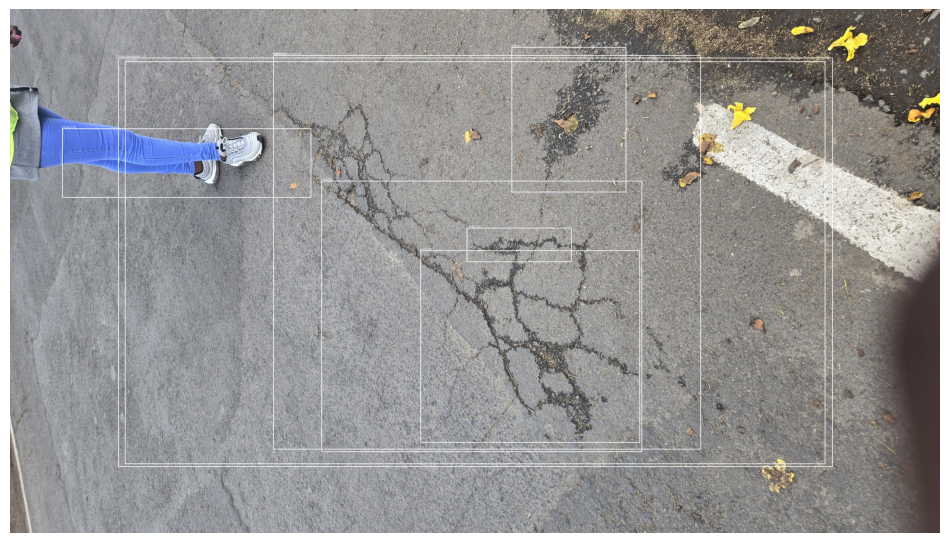

In [11]:
# ---------------------------------------------------------
# Run one test image through the exported model
# ---------------------------------------------------------

CLASS_NAMES = {
    1: "Crack",
    2: "Pothole",
    3: "Surface deterioration",
}

SCORE_THRESHOLD = 0.30

if (
    SAMPLE_IMAGE is not None
    and SAVED_MODEL_DIR.exists()
):

    image, outputs, elapsed = (
        run_savedmodel_inference(
            SAMPLE_IMAGE
        )
    )

    boxes = (
        outputs["detection_boxes"][0]
        .numpy()
    )

    classes = (
        outputs["detection_classes"][0]
        .numpy()
        .astype(int)
    )

    scores = (
        outputs["detection_scores"][0]
        .numpy()
    )

    num = int(
        outputs["num_detections"][0]
        .numpy()
    )

    display_image = image.copy()

    draw = ImageDraw.Draw(
        display_image
    )

    width, height = (
        display_image.size
    )

    shown = 0

    for i in range(num):

        if scores[i] < SCORE_THRESHOLD:
            continue

        ymin, xmin, ymax, xmax = (
            boxes[i]
        )

        left = int(xmin * width)
        top = int(ymin * height)
        right = int(xmax * width)
        bottom = int(ymax * height)

        class_id = int(classes[i])

        label = CLASS_NAMES.get(
            class_id,
            f"Class {class_id}"
        )

        draw.rectangle(
            [
                left,
                top,
                right,
                bottom
            ],
            width=3
        )

        draw.text(
            (
                left,
                max(0, top - 12)
            ),
            f"{label}: {scores[i]:.2f}"
        )

        print(
            f"{label} | "
            f"confidence={scores[i]:.3f}"
        )

        shown += 1

    print(
        f"\nDetections shown: {shown}"
    )

    print(
        f"Inference time: "
        f"{elapsed * 1000:.2f} ms"
    )

    plt.figure(
        figsize=(12, 8)
    )

    plt.imshow(
        display_image
    )

    plt.axis("off")

    plt.show()

else:

    print(
        "Sample image or SavedModel "
        "is unavailable."
    )

## 8. Deployment Handoff to Flask

The final deployment flow is:

```text
Google Colab
    ↓
trained checkpoint
    ↓
SavedModel / optional TFLite
    ↓
models/ in application repository
    ↓
Flask inference service
    ↓
class + confidence + bounding box
    ↓
relative visual severity
    ↓
MongoDB
    ↓
engineer review
```

### Application-side confirmation required

Before the web application is connected to the final model, confirm:

1. **Model artifact path** expected by `backend/app/services/inference.py`.
2. **Model format** actually used: SavedModel and/or TFLite.
3. **Input shape** and datatype.
4. **Output tensor names and shapes**.
5. **Class ID mapping**:
   - 1 = Crack
   - 2 = Pothole
   - 3 = Surface deterioration
6. **Confidence threshold** used by the backend.
7. **Bounding-box coordinate convention** expected by the backend.
8. Whether the backend's severity calculation uses the same image dimensions/box coordinates.
9. Whether the backend stores the model confidence separately from relative visual severity.

Do not change the model class mapping in the backend independently of `configs/label_map.pbtxt`.